## Plot the time evolution of parameters around the shock, relative to the MHD shock

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.lines as mlines

from transform_data import get_transformed_data, get_shock_mask
from field_config import field_labels, field_scales

import flash_amr_tools
import h5py

In [21]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]
sim_names = ["ISM-v30-MHD",  "ISM-v30-MDiff", "ISM-v30", "ISM-v30-HDiff", "ISM-v100"]


# list of fields we want to plot 1D slice of
fields = [ "dens", "pres", "vel", "mag"]

# times = [150, 300, 500] * u.kyr
# times = [50, 100, 200] * u.kyr
times = [30, 90, 120, 180] * u.kyr
times_lss = ["-", "--", ":"]

textpos_y = {
    "dens" : 4e-24,
    "vel" : 1e4,
    "temp" : 1e9,
    "pres" : 3e5,
    "mag" : 2e-5
}

field_lims = {
    "dens" : [1e-27, 1e-23],
    "temp" : [1e3, 1e10],
    "pres" : [1e2, 1e6],
    "vel" : [1e-1, 5e4],
    "mag" : [1e-8, 5e-5],
}

In [22]:
def get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns):

    field_slice = flash_amr_tools.get_slice(
        field_data,
        pos=0.0,
        axis=2,
        ref_lvl=ref_lvl,
        bbox=bbox,
        bsize=bsize,
        brefs=brefs,
        bns=bns,
    )
    # find zero value of y since we cannot slice again
    y_idx = np.digitize(0.0, yarr, right=True)
    return field_slice[:, y_idx]

def find_hdf5_file_from_time(time, sim_dir):
    """
    Find the HDF5 file corresponding to the given time in the simulation directory.
    """
    for file in os.listdir(sim_dir):
        if file.find("hdf5") != -1:
            pf = h5py.File(os.path.join(sim_dir, file), "r")
            time_from_file = (pf['real scalars'][0][1] * u.s).to(u.kyr)
            if np.isclose(time, time_from_file.value, atol=0.1):
                return os.path.join(sim_dir, file)
            
    return None

def find_shock_pos(pf, blist, bbox, bsize, brefs, bns, ref_lvl, shock="outer"):
    """
    Find shock locations in the given HDF5 file.
    """
    # get size of x and y
    cube_size = np.zeros(3, dtype=int)
    cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
    cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
    cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

    # generate arrays for coordinates
    low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
    dxs = (up_cor - low_cor) / cube_size
    xarr = (
        np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
    )
    yarr = (
        np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
    )

        # find the termination and outer shock as well
    shock_data = get_shock_mask(pf, blist, shock=shock)
    shock_1dslice = get_1dslice(shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

    return xarr[(shock_1dslice > 0) & (xarr < 0)], xarr[(shock_1dslice > 0) & (xarr > 0)], xarr, yarr

In [23]:
# get the mean shock position for MHD case first
outer_shock_pos_mhd = np.zeros(len(times))
for it, time in enumerate(times):
    sim_dir = os.path.join(flash_output_dir, bowshock_config["ISM-v30-MHD"]["sim_dir"])

    # find the HDF5 file corresponding to the time
    sim_file = find_hdf5_file_from_time(time.value, sim_dir)

    blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

    # open file to get the coordinate information
    pf = h5py.File(sim_file, "r")
    print(f"List of variables in file: {list(pf.keys())}")
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]

    outer_shock_lt0, _, xarr, yarr = find_shock_pos(
        pf, blist, bbox, bsize, brefs, bns, ref_lvl, shock="outer"
    )
    outer_shock_pos_mhd[it] = np.mean(outer_shock_lt0)

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
12812 12812
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 14496
Region extended to:	lower		upper
	x	-7.71419381e+19		+2.31425806e+20
	y	-7.71419381e+19		+7.71419381e+19
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
List of variables in file: ['active', 'amass', 'bflags', 'block size', 'bounding bo

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
12812 12812
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 14496
Region extended to:	lower		upper
	x	-7.71419381e+19		+2.31425806e+20
	y	-7.71419381e+19		+7.71419381e+19
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
List of variables in file: ['active', 'amass', 'bflags', 'block size', 'bounding bo

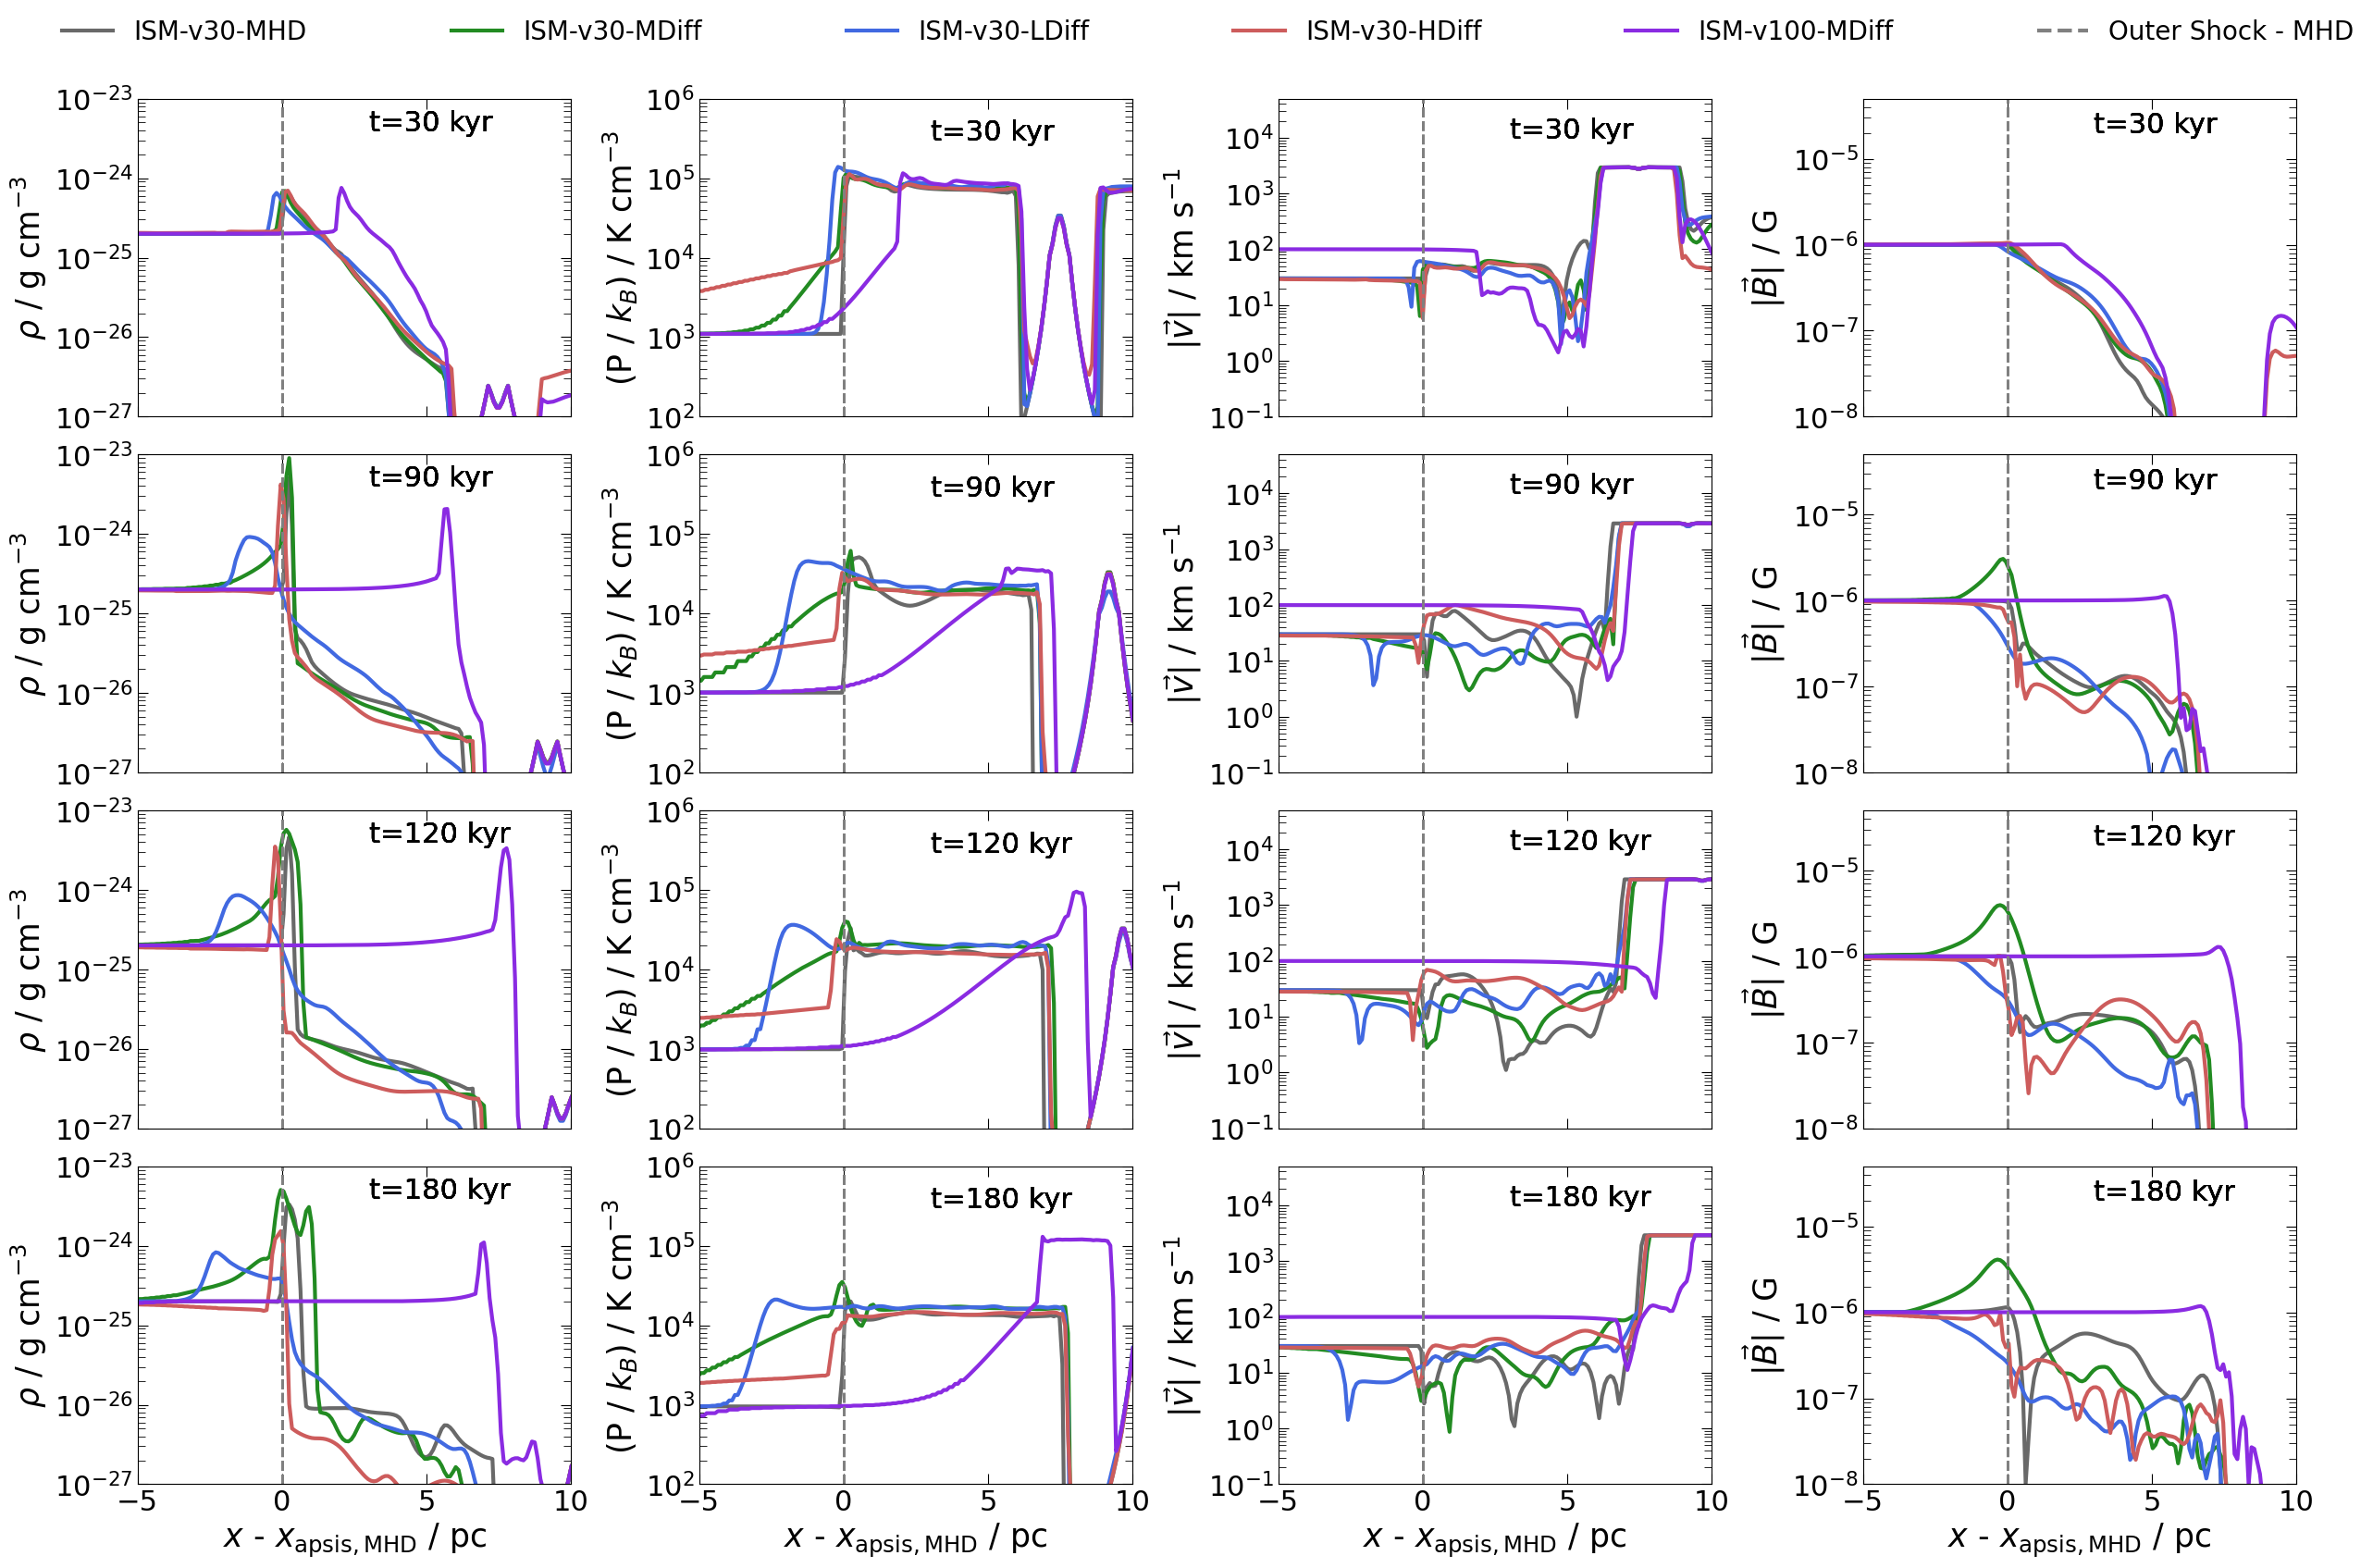

In [24]:
fig = plt.figure(figsize=(25, 16), constrained_layout=True)
gs = fig.add_gridspec(len(times),len(fields), hspace=0, wspace=0.02)
axs = gs.subplots(sharex=True, sharey=False)

axs_flattened = axs.flatten()
sim_handles = []
# time_handles = []
# initial parameters
for sim_name in sim_names:
    for it, time in enumerate(times):

        sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

        # find the HDF5 file corresponding to the time
        sim_file = find_hdf5_file_from_time(time.value, sim_dir)

        blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

        # open file to get the coordinate information
        pf = h5py.File(sim_file, "r")
        print(f"List of variables in file: {list(pf.keys())}")
        ref_lvl = pf["refine level"][()][blist]
        bbox = pf["bounding box"][()][blist]
        bsize = pf["block size"][()][blist]

        _, _, xarr, yarr = find_shock_pos(
            pf, blist, bbox, bsize, brefs, bns, ref_lvl, shock="outer"
        )
    
        # now loop over different fields and plot
        for i, field in enumerate(fields):
            field_data = get_transformed_data(pf, field, blist)
            field_1dslice = get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

            # plot
            axs_flattened[len(fields) * it + i].plot(
                ((xarr - outer_shock_pos_mhd[it]) * u.cm).to(u.pc),
                field_1dslice,
                lw=3.0,
                color=bowshock_config[sim_name]["color"],
                ls="-"
            )

            # limits
            axs_flattened[len(fields) * it + i].set_xlim(xmin=-5, xmax=10)
            axs_flattened[len(fields) * it + i].set_ylim(field_lims[field])

            # scale
            axs_flattened[len(fields) * it + i].set_yscale(field_scales[field])

            # labels
            axs_flattened[len(fields) * it + i].set_ylabel(field_labels[field], fontsize=25)

            # ticks
            axs_flattened[len(fields) * it + i].tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=22,
                top=True,
                right=True,
            )
            axs_flattened[len(fields) * it + i].tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=18,
                top=True,
                right=True,
            )

            axs_flattened[len(fields) * it + i].axvline(
                0.0, ls="--", lw=2.0, color="gray"
            )

            axs_flattened[len(fields) * it + i].annotate(f"t={time.value:.0f} kyr", xy=(3, textpos_y[field]), fontsize=22)

            if (len(fields) * it + i) >= len(axs_flattened)-len(fields):  # TODO: change this to a more general condition
                axs_flattened[len(fields) * it + i].set_xlabel("$x$ - $x_\mathrm{apsis, MHD}$ / pc", fontsize=25)


    sim_handles.append(
        mlines.Line2D(
            [0], [0], lw=3.0, color=bowshock_config[sim_name]["color"], label=bowshock_config[sim_name]["label"]
        )
    )

#         # time_handles.append(
#         #     mlines.Line2D(
#         #         [0], [0], lw=3.0, color="k", label=f"t={time:.0f}", ls=times_lss[it]
#         #     )
#         # )

# # handles = [sim_handles[0], sim_handles[1], mlines.Line2D(
# #             [0], [0], lw=3.0, color="k", label="Outer Shock", ls="--"
# #         ),
# #         mlines.Line2D(
# #             [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
# #         )]
sim_handles.append(
    mlines.Line2D(
        [0], [0], lw=3.0, color="gray", label="Outer Shock - MHD", ls="--"
    )
)
# sim_handles.append(
#     mlines.Line2D(
#         [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
#     )
# )
fig.legend(handles=sim_handles, prop={"size":20},  ncol=6, frameon=False, borderaxespad=0.0, mode='expand', loc="upper left", bbox_to_anchor=(0.02, 1.05, 1, 0),)
# # fig.subplots_adjust(top=0.88)
# # axs_flattened[6].set_xlabel("$x$ / pc", fontsize=25)

# #     axs[0].annotate(f"t={time:.0f}", xy=(18.5, 3e-29), fontsize=24)


# # fig.legend(handles=time_handles, prop={"size":14})

fig.savefig(f"{fig_dir}/1dslice_all_nearshock.pdf", dpi=300, bbox_inches="tight")